# Modelo baseline para la predicción de churn

**Proyecto:** Predicción de abandono de clientes (Telco Customer Churn)  
**Etapa:** Modelado inicial y evaluación de referencia

## Resumen

En esta etapa se construye un baseline reproducible para estimar si un cliente abandonará el servicio (`Churn`). Se compara un clasificador Dummy, que predice la clase mayoritaria, con una regresión logística. El objetivo no es seleccionar todavía un modelo para producción, sino establecer una referencia cuantitativa para experimentos posteriores.

El EDA y la preparación inicial están documentados en `01_exploracion_inicial_churn.ipynb` y `02_preparacion_datos_churn.ipynb`. Primero ejecuta el notebook 02, que guarda el conjunto preparado en `data/processed/telco_churn_preparado.csv`. Este notebook reutiliza ese artefacto: no repite el EDA ni vuelve a convertir `TotalCharges`.

## Objetivo y alcance

Se reutiliza el conjunto preparado en el notebook 02; no se repiten el análisis exploratorio ni la conversión de `TotalCharges`. Se definen las variables predictoras y la variable objetivo, se separan los datos en entrenamiento y prueba, y se integran la imputación, el escalado y la codificación en pipelines para evitar fuga de información.

La evaluación se realiza sobre una partición de prueba estratificada del 20 %, con `random_state=31`. La clase positiva para las métricas de precision, recall, F1 y ROC-AUC es `Yes` (cliente que abandonó).

Esta etapa no incluye ajuste de hiperparámetros, validación cruzada, seguimiento con MLflow ni despliegue. Las asociaciones observadas por el modelo no deben interpretarse como causas del abandono.

## 1. Carga del conjunto preparado

El notebook reutiliza el archivo `data/processed/telco_churn_preparado.csv`, exportado al finalizar `02_preparacion_datos_churn.ipynb`. Esta separación evita repetir la limpieza. La validación confirma 7.043 filas, 21 columnas, `TotalCharges` numérica y 11 valores faltantes.

In [45]:
from pathlib import Path
import pandas as pd

ruta_preparada = (
    Path.cwd()
    / "data"
    / "processed"
    / "telco_churn_preparado.csv"
)

if not ruta_preparada.exists():
    raise FileNotFoundError(
        "No se encontró el conjunto preparado. Ejecuta primero "
        "02_preparacion_datos_churn.ipynb."
    )

df = pd.read_csv(ruta_preparada)

print("Dimensiones:", df.shape)
print("Tipo de TotalCharges:", df["TotalCharges"].dtype)
print("Faltantes en TotalCharges:", df["TotalCharges"].isna().sum())

Dimensiones: (7043, 21)
Tipo de TotalCharges: float64
Faltantes en TotalCharges: 11


## 2. Tratamiento inicial de `TotalCharges` faltante

Se identificaron 11 faltantes en `TotalCharges` (0,16 % del conjunto); todos corresponden a registros con `tenure = 0` y `Churn = No`. Se conservan las filas para no excluir observaciones válidas. Para este baseline, el imputador numérico utiliza la mediana, calculada únicamente durante el ajuste con los datos de entrenamiento.

La elección es provisional: una mediana puede no representar el cargo acumulado de clientes con antigüedad cero. En una iteración posterior se podrá comparar con una imputación de cero, siempre que el significado de negocio de esos registros justifique esa alternativa.

## 3. Construcción de `X` e `y`

De acuerdo con la decisión documentada en `02_preparacion_datos_churn.ipynb`, `Churn` es la variable objetivo y `customerID` se conserva en el conjunto preparado como identificador, pero no se usa como predictor. Así, `X` contiene las 19 características candidatas y `y` contiene la etiqueta que el modelo debe predecir.

In [46]:
columna_objetivo = "Churn"
columna_id = "customerID"

y = df[columna_objetivo]
X = df.drop(columns=[columna_objetivo, columna_id])

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Categorías de Churn:", y.value_counts().to_dict())

Dimensiones de X: (7043, 19)
Dimensiones de y: (7043,)
Categorías de Churn: {'No': 5174, 'Yes': 1869}


## 4. Separación de entrenamiento y prueba

El 80 % de los datos se utiliza para entrenar y el 20 % se reserva para la evaluación final. La partición es estratificada para conservar la proporción de `Churn` en ambos subconjuntos; `random_state=31` permite reproducirla. Los transformadores se ajustan después de la partición, dentro de los pipelines, para evitar fuga de información.

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=31,
    stratify=y,
)

# Proporción de Churn en y_train y y_test
print("Proporción de Churn en y_train (%):")
print(y_train.value_counts(normalize=True).mul(100).round(3))

print("\nProporción de Churn en y_test (%):")
print(y_test.value_counts(normalize=True).mul(100).round(3))

Proporción de Churn en y_train (%):
Churn
No     73.465
Yes    26.535
Name: proportion, dtype: float64

Proporción de Churn en y_test (%):
Churn
No     73.456
Yes    26.544
Name: proportion, dtype: float64


## 5. Preprocesamiento sin fuga de información

Las variables numéricas requieren imputación de `TotalCharges` y escalado para la regresión logística. Las categóricas requieren imputación y codificación one-hot. Un `ColumnTransformer` dentro de un `Pipeline` permite ajustar estas transformaciones solo con `X_train` y aplicar después lo aprendido a `X_test`.

El preprocesamiento distingue variables numéricas y categóricas. Para las numéricas, el pipeline imputa faltantes con la mediana y estandariza las escalas. Para las categóricas, imputa con la categoría más frecuente y aplica codificación one-hot; `handle_unknown="ignore"` permite procesar categorías nuevas en evaluación. `ColumnTransformer` combina ambos flujos y, al estar dentro del pipeline del modelo, ajusta sus parámetros solo con `X_train`.

In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

var_num = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
var_cat = X_train.select_dtypes(include=["str", "object", "category"]).columns.tolist()

pipeline_num = Pipeline(steps=[
    ("imputar_num", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

pipeline_cat = Pipeline(steps=[
    ("imputar_cat", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocesador = ColumnTransformer(transformers=[
    ("num", pipeline_num, var_num),
    ("cat", pipeline_cat, var_cat),
])

print(f"Variables numéricas: {len(var_num)}")
print(f"Variables categóricas: {len(var_cat)}")

Variables numéricas: 4
Variables categóricas: 15


## 6. Modelos de referencia

Primero se utilizará `DummyClassifier` como referencia sencilla: predice siempre la clase más frecuente y ayuda a comprobar si un modelo aprende patrones útiles. Luego se comparará con una regresión logística, usando el mismo preprocesamiento.

Se comparan dos referencias: `DummyClassifier(strategy="most_frequent")`, que siempre predice la clase más frecuente, y una regresión logística sin ponderación adicional de clases. Ambos modelos reciben el mismo preprocesamiento y se ajustan exclusivamente con los datos de entrenamiento. `class_weight="balanced"` queda como una variante experimental futura, no se incorpora a este baseline.

In [49]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression


pipeline_dummy = Pipeline(steps=[
    ("preprocesador", clone(preprocesador)),
    ("dummy", DummyClassifier(strategy="most_frequent"))
])

pipeline_lr = Pipeline(steps=[
    ("preprocesador", clone(preprocesador)),
    ("logistic_regression", LogisticRegression(max_iter=1000, random_state=31)),
])

pipeline_dummy.fit(X_train, y_train)
y_pred_dummy = pipeline_dummy.predict(X_test)
pipeline_lr.fit(X_train, y_train)
y_pred_lr = pipeline_lr.predict(X_test)



## 7. Evaluación del baseline

Se reportan accuracy, precision, recall y F1 para la clase positiva `Yes`, además de ROC-AUC calculado con la probabilidad de esa clase. La exactitud por sí sola puede resultar engañosa debido al desbalance de clases. La matriz de confusión permite distinguir falsos negativos (clientes que abandonaron y fueron predichos como `No`) de falsos positivos (clientes que permanecieron y fueron predichos como `Yes`).

El Dummy no predice ningún `Yes`; por ello, precision, recall y F1 para esa clase son cero y su ROC-AUC es 0,5. Estos valores son esperables para este clasificador y sirven para establecer la referencia.

In [50]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
metricas_dummy = {
    "accuracy": accuracy_score(y_test, y_pred_dummy),
    "precision": precision_score(
        y_test, y_pred_dummy, pos_label="Yes", zero_division=0
    ),
    "recall": recall_score(
        y_test, y_pred_dummy, pos_label="Yes", zero_division=0
    ),
    "f1": f1_score(y_test, y_pred_dummy, pos_label="Yes", zero_division=0),
}

metricas_lr = {
    "accuracy": accuracy_score(y_test, y_pred_lr),
    "precision": precision_score(
        y_test, y_pred_lr, pos_label="Yes", zero_division=0
    ),
    "recall": recall_score(
        y_test, y_pred_lr, pos_label="Yes", zero_division=0
    ),
    "f1": f1_score(y_test, y_pred_lr, pos_label="Yes", zero_division=0),
}

predict_proba_dummy = pipeline_dummy.predict_proba(X_test)
predict_proba_lr = pipeline_lr.predict_proba(X_test)
indice_yes_dummy = list(pipeline_dummy.classes_).index("Yes")
indice_yes_lr = list(pipeline_lr.classes_).index("Yes")
y_test_binario = y_test.eq("Yes").astype(int)

metricas_dummy["roc_auc"] = roc_auc_score(
    y_test_binario, predict_proba_dummy[:, indice_yes_dummy]
)
metricas_lr["roc_auc"] = roc_auc_score(
    y_test_binario, predict_proba_lr[:, indice_yes_lr]
)


df_metricas = pd.DataFrame(
    [metricas_dummy, metricas_lr],
    index=["Dummy (clase mayoritaria)", "Regresión logística"],
).rename(
    columns={
        "accuracy": "Accuracy",
        "precision": "Precision (Yes)",
        "recall": "Recall (Yes)",
        "f1": "F1 (Yes)",
        "roc_auc": "ROC-AUC",
    }
)

df_metricas.round(3)

,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),ROC-AUC
Dummy (clase mayoritaria),0.735,0.000,0.0,0.000,0.500
Regresión logística,0.784,0.613,0.5,0.551,0.826


### Matrices de confusión

En cada gráfico, las filas representan la clase real y las columnas la predicción. La diagonal corresponde a aciertos; fuera de ella están los errores. Se presenta el Dummy junto con la regresión logística para que la comparación use las mismas clases y el mismo conjunto de prueba.

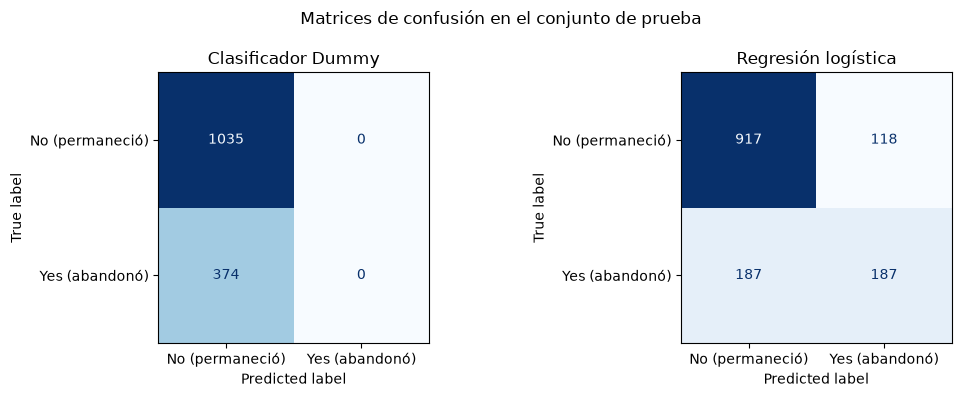

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dummy,
    labels=["No", "Yes"],
    display_labels=["No (permaneció)", "Yes (abandonó)"],
    cmap="Blues",
    values_format="d",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Clasificador Dummy")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=["No", "Yes"],
    display_labels=["No (permaneció)", "Yes (abandonó)"],
    cmap="Blues",
    values_format="d",
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Regresión logística")

fig.suptitle("Matrices de confusión en el conjunto de prueba")
fig.tight_layout()
plt.show()

## 8. Conclusiones y próximos pasos

### Hallazgos

Se conservaron las 7.043 observaciones y se imputaron los 11 valores faltantes de `TotalCharges` con la mediana, aprendida dentro del pipeline de entrenamiento. La partición estratificada mantuvo una proporción cercana al 73,5 % de `No` y 26,5 % de `Yes` tanto en entrenamiento como en prueba.

La regresión logística superó al clasificador Dummy en la partición de prueba: obtuvo accuracy de **0,784** frente a **0,735**, precision de **0,613**, recall de **0,500**, F1 de **0,551** y ROC-AUC de **0,826**. El Dummy alcanzó accuracy de **0,735**, pero recall y F1 de **0** para `Yes`, porque predice siempre `No`. Su accuracy refleja principalmente la proporción de la clase mayoritaria y no una capacidad útil para detectar abandonos.

La matriz de confusión de la regresión logística contiene 917 verdaderos negativos, 118 falsos positivos, 187 falsos negativos y 187 verdaderos positivos. Por tanto, el modelo identifica la mitad de los clientes que abandonaron en el conjunto de prueba, pero deja sin detectar la otra mitad. La precisión de 0,613 indica que alrededor del 61 % de las predicciones de abandono fueron correctas.

### Interpretación y limitaciones

El ROC-AUC de 0,826 sugiere que la regresión logística discrimina mejor que el azar entre clientes con y sin abandono en esta partición. No obstante, el recall de 0,500 muestra margen importante para detectar más casos `Yes`. La métrica prioritaria dependerá del costo relativo de no contactar a un cliente que se va (falso negativo) frente al de contactar a quien permanecería (falso positivo); ese criterio de negocio aún no se ha definido.

Estos resultados corresponden a una sola partición aleatoria y a una configuración inicial. No demuestran causalidad ni garantizan el mismo desempeño en nuevos datos. La imputación por mediana es provisional y no se han ajustado hiperparámetros ni evaluado variabilidad mediante validación cruzada. Por ello, este baseline es una referencia técnica, no una decisión de producción.

